# 1. Setup e Parametri Generali

In [1]:
import gurobipy as gp
from gurobipy import GRB
import math
import random
import matplotlib.pyplot as plt


random.seed(42)                                                 #Fissa il seed per la generazione

num_clienti = 20                                                #numero di nodi nel grafo 
num_drones = 2                                                  #numero di droni nella flotta
speed_truck = 25.0                                              #velocità media del camion
speed_drone = 25.0                                              #velocità media del singolo drone
max_endurance_min = 30.0                                        #durata massima del volo in minuti 
max_radius = (max_endurance_min / 60.0) * speed_drone / 2.0     #distanza max in miglia percorribile dal drone

# 2. Generazione casuale dei clienti

In [2]:

C = list(range(1, num_clienti + 1))                             #insieme di tutti i clienti
c_nodes = len(C)                                                #numero di nodi 
N0 = [0] + C                                                    #Nodo di partenza  
Nplus = C + [c_nodes + 1]                                       #Nodo di ritorno al deposito (è lo stesso di partenza)
V = list(range(1, num_drones + 1))                              #Lista dei droni 

coords = {}
coords[0] = (0, 0)                                                #Deposito partenza
coords[c_nodes + 1] = (0, 0)                                      #Deposito arrivo

C_second = []                                                     #Insieme dei clienti idonei al drone

print("="*60)
print("--- GENERAZIONE CASUALE DEI CLIENTI ---")
for i in C:
    # Genera coordinate casuali tra -8 e 8 miglia
    x = random.uniform(-8, 8)
    y = random.uniform(-8, 8)
    coords[i] = (x, y)
    
    dist_from_depot = math.hypot(x, y)
    weight_eligible = random.random() < 0.8  # 80% di probabilità
    
    
    if dist_from_depot <= max_radius and weight_eligible:       # Controllo logico (AND) su distanza e peso
        C_second.append(i)
        print(f"Cliente {i}: Dist. {dist_from_depot:.2f} mi | Peso OK -> IDONEO AL DRONE")
    else:
        motivo = "Fuori raggio" if dist_from_depot > max_radius else "Pacco troppo pesante"
        print(f"Cliente {i}: Dist. {dist_from_depot:.2f} mi | -> NON IDONEO ({motivo})")

print("="*60)

--- GENERAZIONE CASUALE DEI CLIENTI ---
Cliente 1: Dist. 7.92 mi | -> NON IDONEO (Fuori raggio)
Cliente 2: Dist. 5.82 mi | Peso OK -> IDONEO AL DRONE
Cliente 3: Dist. 9.11 mi | -> NON IDONEO (Fuori raggio)
Cliente 4: Dist. 8.77 mi | -> NON IDONEO (Fuori raggio)
Cliente 5: Dist. 8.98 mi | -> NON IDONEO (Fuori raggio)
Cliente 6: Dist. 4.53 mi | Peso OK -> IDONEO AL DRONE
Cliente 7: Dist. 9.32 mi | -> NON IDONEO (Fuori raggio)
Cliente 8: Dist. 4.07 mi | Peso OK -> IDONEO AL DRONE
Cliente 9: Dist. 7.77 mi | -> NON IDONEO (Fuori raggio)
Cliente 10: Dist. 8.52 mi | -> NON IDONEO (Fuori raggio)
Cliente 11: Dist. 6.14 mi | Peso OK -> IDONEO AL DRONE
Cliente 12: Dist. 7.82 mi | -> NON IDONEO (Fuori raggio)
Cliente 13: Dist. 5.60 mi | -> NON IDONEO (Pacco troppo pesante)
Cliente 14: Dist. 3.50 mi | Peso OK -> IDONEO AL DRONE
Cliente 15: Dist. 5.51 mi | Peso OK -> IDONEO AL DRONE
Cliente 16: Dist. 7.68 mi | -> NON IDONEO (Fuori raggio)
Cliente 17: Dist. 3.06 mi | Peso OK -> IDONEO AL DRONE
Client

# 3. Calcolo distanze e Matrici dei Tempi

In [3]:
def dist_euclidea(i, j):
    return math.hypot(coords[i][0] - coords[j][0], coords[i][1] - coords[j][1])

# Tempi per il camion (tra tutti i nodi)
tau = {}
for i in N0:
    for j in Nplus:
        if i != j:
            tau[i, j] = (dist_euclidea(i, j) / speed_truck) * 60.0  

# Tempi per il drone (andata e ritorno dal deposito ai nodi idonei)
tau_prime = {}
for i in C_second:
    dist_andata = dist_euclidea(0, i)
    dist_ritorno = dist_euclidea(i, c_nodes+1)
    tau_prime[0, i] = (dist_andata / speed_drone) * 60.0
    tau_prime[i, c_nodes+1] = (dist_ritorno / speed_drone) * 60.0

# 4. Costruzione del Modello Gurobi

In [4]:
m = gp.Model("PDSTSP_Random_Instance")
m.setParam('OutputFlag', 0) # Nasconde il log tecnico di Gurobi

# --- VARIABILI ---
x = m.addVars([(i,j) for i in N0 for j in Nplus if i != j], vtype=GRB.BINARY, name="x")
y = m.addVars([(i,v) for i in C_second for v in V], vtype=GRB.BINARY, name="y")
u = m.addVars(Nplus, lb=1, ub=c_nodes+2, vtype=GRB.CONTINUOUS, name="u")
z = m.addVar(vtype=GRB.CONTINUOUS, name="makespan")

# --- OBIETTIVO ---
m.setObjective(z, GRB.MINIMIZE)

# --- VINCOLI ---
# C34: Il makespan deve essere maggiore o uguale al tempo totale del camion
m.addConstr(z >= gp.quicksum(tau[i,j] * x[i,j] for i in N0 for j in Nplus if i != j), name="C34")

# C35: Il makespan deve coprire i tempi di volo di ciascun drone
for v in V:
    m.addConstr(z >= gp.quicksum((tau_prime[0,i] + tau_prime[i, c_nodes+1]) * y[i,v] for i in C_second), name=f"C35_v{v}")

# C36: Ogni cliente deve essere visitato esattamente una volta (o dal camion o da un drone)
for j in C:
    truck_visits = gp.quicksum(x[i,j] for i in N0 if i != j)
    drone_visits = gp.quicksum(y[j,v] for v in V) if j in C_second else 0
    m.addConstr(truck_visits + drone_visits == 1, name=f"C36_cliente{j}")

# C37, C38: Vincoli di partenza e arrivo per il deposito
m.addConstr(gp.quicksum(x[0,j] for j in Nplus if j != 0) == 1, name="C37")
m.addConstr(gp.quicksum(x[i, c_nodes+1] for i in N0 if i != c_nodes+1) == 1, name="C38")

# C39: Conservazione del flusso per il camion nei nodi intermedi
for j in C:
    m.addConstr(gp.quicksum(x[i,j] for i in N0 if i != j) == 
                gp.quicksum(x[j,k] for k in Nplus if k != j), name=f"C39_nodo{j}")

# C40: Vincoli MTZ (Miller-Tucker-Zemlin) per l'eliminazione dei sub-tour
BigM = c_nodes + 2
for i in C:
    for j in Nplus:
        if i != j:
            m.addConstr(u[i] - u[j] + 1 <= BigM * (1 - x[i,j]), name=f"C40_MTZ_{i}_{j}")

Set parameter Username
Set parameter LicenseID to value 2798494
Academic license - for non-commercial use only - expires 2027-03-26


# 5. Risultati finali e output

In [5]:
m.optimize()

print("\n" + "="*60)
if m.status == GRB.OPTIMAL:
    print(f"OTTIMO TROVATO! Makespan (Tempo rientro ultimo veicolo): {z.X:.2f} min")
    print("="*60)
    print(f"Tempo di calcolo Gurobi: {m.Runtime:.4f} secondi")
    
    print("\n--- PERCORSO DEL CAMION ---")
    camion_time = 0
    current_node = 0
    while current_node != c_nodes + 1:
        for j in Nplus:
            if current_node != j and x[current_node, j].X > 0.5:
                print(f"Camion: Nodo {current_node} -> Nodo {j} (Tempo: {tau[current_node,j]:.2f} min)")
                camion_time += tau[current_node, j]
                current_node = j
                break
    print(f">> Tempo totale Camion: {camion_time:.2f} min")

    print("\n--- ASSEGNAZIONI DEI DRONI ---")
    for v in V:
        drone_time = 0
        clienti_serviti = []
        for i in C_second:
            if y[i,v].X > 0.5:
                t_volo = tau_prime[0,i] + tau_prime[i, c_nodes+1]
                clienti_serviti.append(f"Cliente {i} ({t_volo:.2f} min)")
                drone_time += t_volo
        
        if clienti_serviti:
            print(f"Drone {v} serve: " + ", ".join(clienti_serviti))
        else:
            print(f"Drone {v}: Inattivo")
        print(f">> Tempo totale Drone {v}: {drone_time:.2f} min")
else:
    print("Nessuna soluzione ottima trovata.")


OTTIMO TROVATO! Makespan (Tempo rientro ultimo veicolo): 128.66 min
Tempo di calcolo Gurobi: 1.6250 secondi

--- PERCORSO DEL CAMION ---
Camion: Nodo 0 -> Nodo 10 (Tempo: 20.44 min)
Camion: Nodo 10 -> Nodo 4 (Tempo: 24.28 min)
Camion: Nodo 4 -> Nodo 5 (Tempo: 0.77 min)
Camion: Nodo 5 -> Nodo 18 (Tempo: 7.50 min)
Camion: Nodo 18 -> Nodo 16 (Tempo: 6.44 min)
Camion: Nodo 16 -> Nodo 1 (Tempo: 15.89 min)
Camion: Nodo 1 -> Nodo 20 (Tempo: 6.33 min)
Camion: Nodo 20 -> Nodo 7 (Tempo: 6.77 min)
Camion: Nodo 7 -> Nodo 3 (Tempo: 4.43 min)
Camion: Nodo 3 -> Nodo 9 (Tempo: 9.91 min)
Camion: Nodo 9 -> Nodo 12 (Tempo: 1.72 min)
Camion: Nodo 12 -> Nodo 13 (Tempo: 10.74 min)
Camion: Nodo 13 -> Nodo 21 (Tempo: 13.44 min)
>> Tempo totale Camion: 128.66 min

--- ASSEGNAZIONI DEI DRONI ---
Drone 1 serve: Cliente 2 (27.96 min), Cliente 8 (19.55 min), Cliente 11 (29.46 min), Cliente 15 (26.43 min), Cliente 19 (14.12 min)
>> Tempo totale Drone 1: 117.51 min
Drone 2 serve: Cliente 6 (21.75 min), Cliente 14 (

# 6. Visualizzazione Grafica delle rotte  

In [6]:

def disegna_risultato(coords, x, y, C, C_second, c_nodes, V):
    plt.figure(figsize=(10, 10))
    
    # 1. Disegna il deposito
    plt.scatter(coords[0][0], coords[0][1], c='red', marker='*', s=400, label='Deposito', zorder=10)
    
    # 2. Identifica quali clienti sono serviti da chi per applicare i colori corretti
    clienti_camion = []
    clienti_droni = {v: [] for v in V}
    
    for i in C:
        servito_da_drone = False
        if i in C_second:
            for v in V:
                # Se il drone v serve il cliente i
                if y[i, v].X > 0.5:
                    clienti_droni[v].append(i)
                    servito_da_drone = True
        
        # Se non è servito da nessun drone, appartiene al camion
        if not servito_da_drone:
            clienti_camion.append(i)

    # 3. Disegna i clienti del camion
    for i in clienti_camion:
        plt.scatter(coords[i][0], coords[i][1], c='blue', marker='o', s=80, zorder=5)
        plt.annotate(str(i), (coords[i][0] + 0.2, coords[i][1] + 0.2), fontsize=10)
        
    # Aggiunge la voce alla legenda per i clienti del camion (solo una volta)
    if clienti_camion:
        plt.scatter([], [], c='blue', marker='o', s=80, label='Clienti Camion')

    # 4. Traccia il percorso del camion (Linea blu continua)
    truck_label_added = False
    for i, j in x.keys():
        if x[i, j].X > 0.5:
            # Il nodo di arrivo c_nodes + 1 corrisponde al deposito 0
            nodo_dest = 0 if j == c_nodes + 1 else j
            plt.plot([coords[i][0], coords[nodo_dest][0]], 
                     [coords[i][1], coords[nodo_dest][1]], 
                     c='blue', linestyle='-', linewidth=2.5, 
                     label='Percorso Camion' if not truck_label_added else "")
            truck_label_added = True

    # 5. Disegna i clienti e i viaggi dei droni (Verde per Drone 1, Arancione per Drone 2)
    colori_droni = {1: 'green', 2: 'orange'}
    for v in V:
        colore = colori_droni.get(v, 'gray') # Colore di fallback
        
        # Disegna i clienti di questo drone (Quadrati colorati)
        if clienti_droni[v]:
            for i in clienti_droni[v]:
                plt.scatter(coords[i][0], coords[i][1], c=colore, marker='s', s=80, zorder=5)
                plt.annotate(str(i), (coords[i][0] + 0.2, coords[i][1] + 0.2), fontsize=10)
            
            # Voce in legenda per i clienti del drone
            plt.scatter([], [], c=colore, marker='s', s=80, label=f'Clienti Drone {v}')
        
        # Traccia i viaggi in linea d'aria dal deposito al cliente (Linea tratteggiata)
        drone_label_added = False
        for i in clienti_droni[v]:
            plt.plot([coords[0][0], coords[i][0]], 
                     [coords[0][1], coords[i][1]], 
                     c=colore, linestyle='--', linewidth=1.8, alpha=0.6,
                     label=f'Viaggi Drone {v}' if not drone_label_added else "")
            drone_label_added = True

    # Impostazioni grafiche finali
    plt.title("Rotte del Camion e dei Droni")
    plt.xlabel("X (miglia)")
    plt.ylabel("Y (miglia)")
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

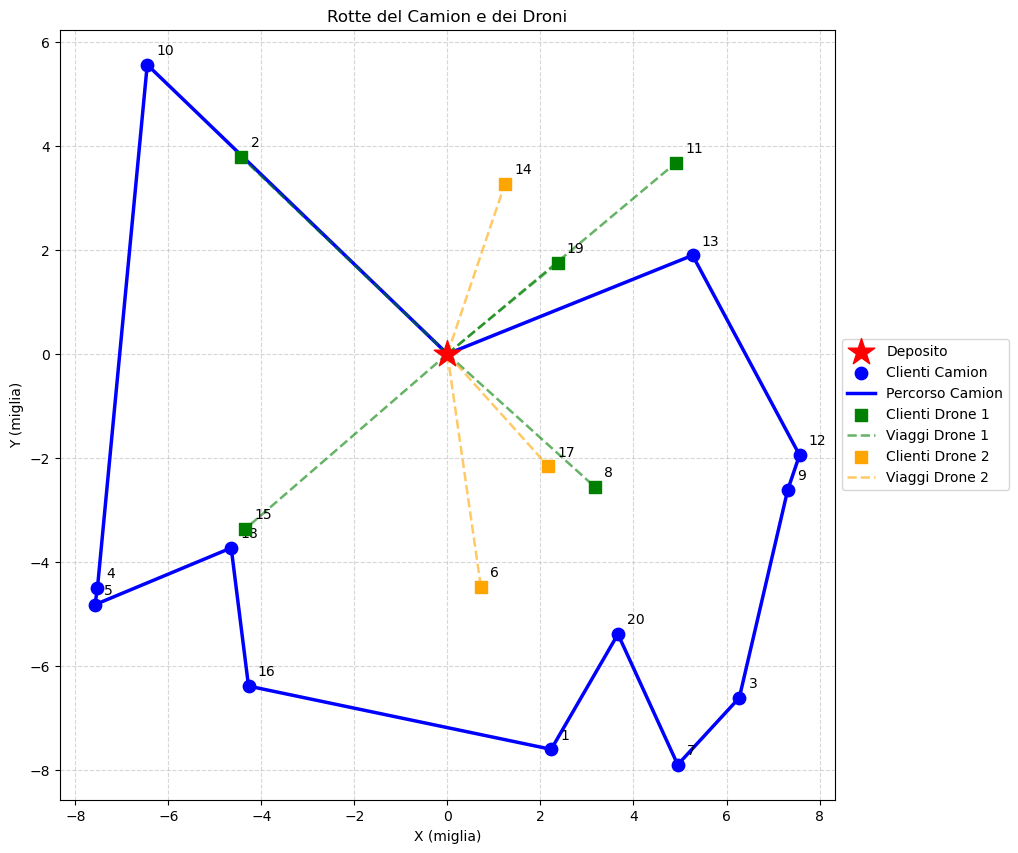

In [7]:
# Genera l'output grafico usando i risultati salvati nelle variabili di Gurobi (x, y)
if m.status == GRB.OPTIMAL:
    disegna_risultato(coords, x, y, C, C_second, c_nodes, V)
else:
    print("Grafo non disponibile: Il solutore non ha trovato una soluzione ottima.")